In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import io

from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

if filename.endswith(".zip"):
    with zipfile.ZipFile(io.BytesIO(uploaded[filename])) as z:
        df = pd.read_csv(z.open("product_info.csv"))
else:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded:", df.shape)

Saving product_info.csv.zip to product_info.csv (2).zip
Dataset loaded: (8494, 27)


In [15]:
print("Number of products:", len(df))
df.head()

Number of products: 8494


,product_id,product_name,brand_id,brand_name,loves_count,rating,reviews,size,variation_type,variation_value,...,online_only,out_of_stock,sephora_exclusive,highlights,primary_category,secondary_category,tertiary_category,child_count,child_max_price,child_min_price
0,P473671,Fragrance Discovery Set,6342,19-69,6320,3.6364,11.0,NaN,NaN,NaN,...,1,0,0,"['Unisex/ Genderless Scent', 'Warm &Spicy Scen...",Fragrance,Value & Gift Sets,Perfume Gift Sets,0,NaN,NaN
1,P473668,La Habana Eau de Parfum,6342,19-69,3827,4.1538,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,85.0,30.0
2,P473662,Rainbow Bar Eau de Parfum,6342,19-69,3253,4.2500,16.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
3,P473660,Kasbah Eau de Parfum,6342,19-69,3018,4.4762,21.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0
4,P473658,Purple Haze Eau de Parfum,6342,19-69,2691,3.2308,13.0,3.4 oz/ 100 mL,Size + Concentration + Formulation,3.4 oz/ 100 mL,...,1,0,0,"['Unisex/ Genderless Scent', 'Layerable Scent'...",Fragrance,Women,Perfume,2,75.0,30.0


In [16]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (8494, 27)

Column names:
['product_id', 'product_name', 'brand_id', 'brand_name', 'loves_count', 'rating', 'reviews', 'size', 'variation_type', 'variation_value', 'variation_desc', 'ingredients', 'price_usd', 'value_price_usd', 'sale_price_usd', 'limited_edition', 'new', 'online_only', 'out_of_stock', 'sephora_exclusive', 'highlights', 'primary_category', 'secondary_category', 'tertiary_category', 'child_count', 'child_max_price', 'child_min_price']

Missing values:
product_id               0
product_name             0
brand_id                 0
brand_name               0
loves_count              0
rating                 278
reviews                278
size                  1631
variation_type        1444
variation_value       1598
variation_desc        7244
ingredients            945
price_usd                0
value_price_usd       8043
sale_price_usd        8224
limited_edition          0
new                      0
online_only              0
out_of_stock             0


In [17]:
# Select skincare products
skincare = df[df["primary_category"] == "Skincare"].copy()

# Keep the columns we need
skincare = skincare[
    ["product_id", "product_name", "brand_name",
     "price_usd", "rating", "reviews"]
]

print("Skincare products:", len(skincare))
print("\nMissing values:")
print(skincare.isnull().sum())

print("\nDuplicate products:",
      skincare["product_id"].duplicated().sum())

skincare.head()

Skincare products: 2420

Missing values:
product_id       0
product_name     0
brand_name       0
price_usd        0
rating          69
reviews         69
dtype: int64

Duplicate products: 0


,product_id,product_name,brand_name,price_usd,rating,reviews
89,P439055,GENIUS Sleeping Collagen Moisturizer,Algenist,98.0,4.5413,1321.0
90,P421277,GENIUS Liquid Collagen Serum,Algenist,115.0,4.0259,1159.0
91,P467602,Triple Algae Eye Renewal Balm Eye Cream,Algenist,68.0,4.5306,1142.0
92,P432045,GENIUS Liquid Collagen Lip Treatment,Algenist,29.0,3.8721,649.0
93,P311143,SUBLIME DEFENSE Ultra Lightweight UV Defense F...,Algenist,28.0,4.4134,508.0


Data Cleaning
I selected only skincare products because my project is about skincare prices and ratings. I found 69 products without ratings. I will remove these rows because I cannot compare their ratings with prices. I also checked for duplicate product IDs and did not find any.

In [18]:
# Remove products without ratings
skincare_clean = skincare.dropna(subset=["rating"]).copy()

print("Before cleaning:", len(skincare))
print("After cleaning:", len(skincare_clean))
print("Removed rows:", len(skincare) - len(skincare_clean))

skincare_clean.head()

Before cleaning: 2420
After cleaning: 2351
Removed rows: 69


,product_id,product_name,brand_name,price_usd,rating,reviews
89,P439055,GENIUS Sleeping Collagen Moisturizer,Algenist,98.0,4.5413,1321.0
90,P421277,GENIUS Liquid Collagen Serum,Algenist,115.0,4.0259,1159.0
91,P467602,Triple Algae Eye Renewal Balm Eye Cream,Algenist,68.0,4.5306,1142.0
92,P432045,GENIUS Liquid Collagen Lip Treatment,Algenist,29.0,3.8721,649.0
93,P311143,SUBLIME DEFENSE Ultra Lightweight UV Defense F...,Algenist,28.0,4.4134,508.0


In [19]:
# Check prices and ratings
print("Price statistics:")
print(skincare_clean["price_usd"].describe())

print("\nRating statistics:")
print(skincare_clean["rating"].describe())

print("\nProducts with invalid prices:",
      (skincare_clean["price_usd"] <= 0).sum())

print("Products with invalid ratings:",
      (~skincare_clean["rating"].between(0, 5)).sum())

Price statistics:
count    2351.000000
mean       59.859103
std        69.421428
min         3.000000
25%        28.000000
50%        44.000000
75%        69.000000
max      1900.000000
Name: price_usd, dtype: float64

Rating statistics:
count    2351.00000
mean        4.22889
std         0.47184
min         1.00000
25%         4.00920
50%         4.31110
75%         4.53880
max         5.00000
Name: rating, dtype: float64

Products with invalid prices: 0
Products with invalid ratings: 0


Statistical Analysis
I want to see if expensive skincare products have better ratings. The average price is about $59.86, and the average rating is 4.23 out of 5. The most expensive product costs $1,900, so some products are much more expensive than others. Now I will check if price and rating are connected.

In [20]:
# Check the relationship between price and rating
correlation = skincare_clean["price_usd"].corr(
    skincare_clean["rating"]
)

print("Correlation between price and rating:", round(correlation, 3))

# Compare less expensive and more expensive products
median_price = skincare_clean["price_usd"].median()

affordable = skincare_clean[
    skincare_clean["price_usd"] <= median_price
]

expensive = skincare_clean[
    skincare_clean["price_usd"] > median_price
]

print("Median price: $", median_price)
print("Average rating of affordable products:",
      round(affordable["rating"].mean(), 2))
print("Average rating of expensive products:",
      round(expensive["rating"].mean(), 2))

Correlation between price and rating: -0.005
Median price: $ 44.0
Average rating of affordable products: 4.18
Average rating of expensive products: 4.28


### Visualization 1: Price vs. Rating

I want to see how skincare prices and ratings are connected. This chart will help me compare expensive and affordable products.

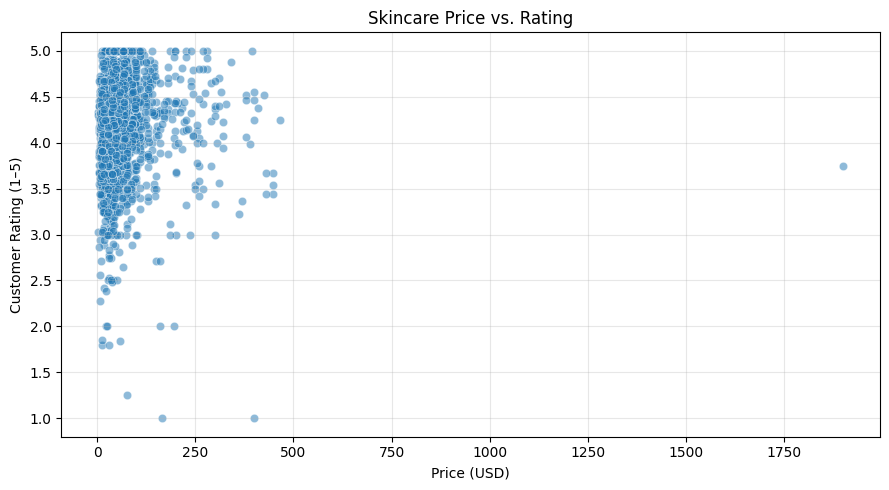

In [21]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=skincare_clean,
    x="price_usd",
    y="rating",
    alpha=0.5
)

plt.title("Skincare Price vs. Rating")
plt.xlabel("Price (USD)")
plt.ylabel("Customer Rating (1–5)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Chart 1: Findings

Most skincare products cost less than $250 and have good ratings. I noticed one very expensive product, but its rating is not the highest. I do not see a clear connection between price and rating. This surprised me because I thought expensive products might have better ratings.

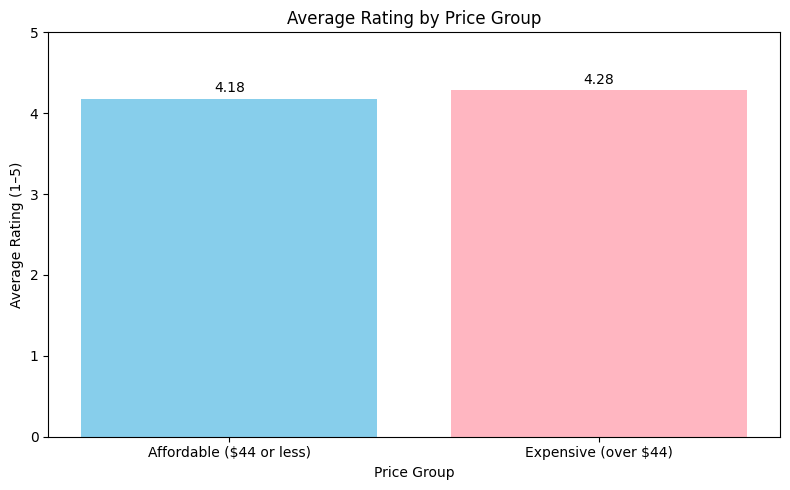

In [22]:
# Compare average ratings
groups = ["Affordable ($44 or less)", "Expensive (over $44)"]

ratings = [
    affordable["rating"].mean(),
    expensive["rating"].mean()
]

plt.figure(figsize=(8, 5))

plt.bar(groups, ratings, color=["skyblue", "lightpink"])

plt.title("Average Rating by Price Group")
plt.xlabel("Price Group")
plt.ylabel("Average Rating (1–5)")
plt.ylim(0, 5)

for i, value in enumerate(ratings):
    plt.text(i, value + 0.08, f"{value:.2f}",
             ha="center")

plt.tight_layout()
plt.show()

### Chart 2: Findings

Expensive skincare products have a slightly higher average rating (4.28) than affordable products (4.18). The difference is only 0.10 points. I think this shows that cheaper skincare products can also have very good ratings.

### Visualization 3: Skincare Price Distribution

I want to see what prices are most common for skincare products. This chart will show how product prices are distributed.

Products over $300: 30


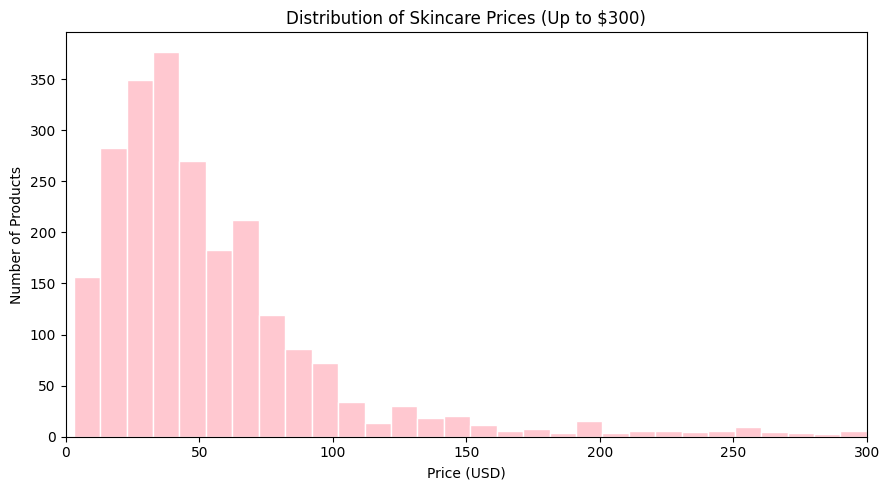

In [23]:
# Count products above the chart limit
over_300 = (skincare_clean["price_usd"] > 300).sum()

print("Products over $300:", over_300)

# Show prices up to $300
plt.figure(figsize=(9, 5))

sns.histplot(
    data=skincare_clean[skincare_clean["price_usd"] <= 300],
    x="price_usd",
    bins=30,
    color="lightpink",
    edgecolor="white"
)

plt.title("Distribution of Skincare Prices (Up to $300)")
plt.xlabel("Price (USD)")
plt.ylabel("Number of Products")
plt.xlim(0, 300)
plt.tight_layout()
plt.show()

### Chart 3: Findings

Most skincare products cost between \$20 and \$50. I can see that cheaper products are much more common than expensive ones. Only 30 products cost more than $300. I did not expect such a big difference in prices.

## Conclusion

I wanted to know if expensive skincare products have better ratings. I analyzed 2,351 skincare products from Sephora.

I found that expensive products have a slightly higher average rating, but the difference is small. The correlation between price and rating is almost zero (-0.005).

I learned that a higher price does not always mean a better customer rating. I would not choose a skincare product based only on its price.

### Limitations

This dataset contains Sephora product information from March 2023. Ratings are based on customer opinions, not scientific tests of product quality. Some products did not have ratings, so I removed them from my analysis. My results may be different with newer data or products from other stores.

## Data Cleaning Log

I started with 8,494 products from the Sephora dataset.

1. I selected only skincare products. This left 2,420 products.
2. I kept six columns: product ID, product name, brand name, price, rating, and number of reviews.
3. I checked for missing values and found 69 products without ratings.
4. I removed these 69 rows because I needed ratings for my analysis.
5. I checked for duplicate product IDs and found none.
6. I checked for invalid prices and ratings. I did not find any.

After cleaning, I had 2,351 skincare products. I kept the original prices and ratings.

In [24]:

# Final cleaning summary

print("Original dataset:", len(df))
print("Skincare products:", len(skincare))
print("Clean skincare products:", len(skincare_clean))
print("Removed missing ratings:",
      len(skincare) - len(skincare_clean))

print("\nMissing values after cleaning:")
print(skincare_clean.isnull().sum())


Original dataset: 8494
Skincare products: 2420
Clean skincare products: 2351
Removed missing ratings: 69

Missing values after cleaning:
product_id      0
product_name    0
brand_name      0
price_usd       0
rating          0
reviews         0
dtype: int64


## Dataset Source and License

I used the Sephora Products and Skincare Reviews dataset from Kaggle.

Dataset: https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews

The data was collected in March 2023. The dataset includes product names, brands, prices, ratings, and other information.

The dataset is shared under the Creative Commons Attribution 4.0 International (CC BY 4.0) license.

## AI Use Disclosure
I used ChatGPT for help with Python code.

## How to Run

1. Download the product_info.csv file from the Kaggle dataset.
2. Open this notebook in Google Colab.
3. Upload the CSV file when prompted.
4. Run the code cells from top to bottom to see the analysis and charts.